# 01 – Signallabor: Signalherkunft und Aktivierung
**Netzdienlichkeit · PEXL · Experimente A und B**

Ziele: Signalquellen vergleichen, binäre und kontinuierliche Aktivierungsfunktionen untersuchen und ein Signal für die Gebäudesimulation auswählen.

**Bedienung:** Lege `signallabor_data.csv` neben beide Notebooks. Öffne das Notebook in Jupyter oder VS Code, wähle einen Python-Kernel und führe die Zellen von oben nach unten mit Shift+Enter aus. Benötigt werden pandas, numpy und matplotlib (`%pip install pandas numpy matplotlib`, falls nötig). Ändere nur die als **EXPERIMENT** gekennzeichneten Parameter und beantworte die Leitfragen in Markdown. Keine eigene Programmierung erforderlich.

Ein Signal $s(t)$ zwischen 0 und 1 beschreibt die **angeforderte zusätzliche Flexibilitätsnutzung**. 0 bedeutet keine zusätzliche Aktivierung (kein generelles Verbrauchsverbot), 1 maximale Aktivierung innerhalb der verfügbaren Flexibilität. Es ist weder eine direkte Leistungsanforderung in kW noch ein Nachweis tatsächlicher Lastverschiebung.

## 1. Ausgangsdaten
| Auswahl | Größe | Freigabe bei |
|---|---|---|
| wind | Onshore-Winderzeugung [MW; Einheit gemäß Generation-by-Type-Konvention] | hohen Werten |
| exaa | Day-Ahead EXAA [€/MWh] | niedrigen Werten |
| mc | Day-Ahead MC [€/MWh] | niedrigen Werten |
| co2 | Strommix-THG-Intensität (LCA) [g CO₂eq/kWh] | niedrigen Werten |
| load_error | Istlast minus Day-Ahead-Prognose [MW] | negativen Werten |

Datengrundlage: bereitgestellte ENTSO-E-Jahresblätter, `exaa.csv`, stündliche MC-Spalten aus `Day Ahead Preise_AT_20-24 - FlexSignale.xlsx`, Electricity Map 2021/2022 (LCA), `Day-ahead Forecast vs. Actual Load [MW].csv`. Die vorhandenen binären Spalten werden nicht verwendet.

**Zeitachse (Draft):** 2021 und 2022, jeweils 8760 Werte ohne Fehlwerte. Wind wird in ursprünglicher chronologischer Reihenfolge übernommen (inkl. doppelter lokaler Herbststunde, ohne leere Schlusszeile). Preis und Lastfehler liegen bereits als 8760-Stunden-Reihen vor; CO₂ liegt in UTC vor. Der gemeinsame Modellzeitstempel ist eine synthetische Stundenachse, keine nachgewiesene zeitzonenrichtige Synchronisation. Vergleiche hier nur Signalstatistiken; vor zeitgenauer gemeinsamer Simulation oder Kreuzkorrelation muss die Zeitbasis mit PEExcel abgeglichen werden. 2020 (Schaltjahr und abweichendes CO₂-Schema) sowie weitere Jahre sind in diesem Draft nicht enthalten.

**Interpretation:** Lastprognosefehler werden rückblickend ausgewertet; sie sind zum Day-Ahead-Zeitpunkt nicht bekannt. Niedrige Preise, niedrige THG-Intensität und hohe Windproduktion sind unterschiedliche Zielgrößen und kein Beleg für lokale Netzentlastung.

In [12]:
%pip install pandas; numpy; matplotlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

data = pd.read_csv(Path("signallabor_data.csv"), parse_dates=["model_timestamp"])
assert data.groupby("year").size().eq(8760).all()
assert not data.isna().any().any()
info = {
    "wind": ("Wind Onshore", "MW", "high"),
    "exaa": ("EXAA", "EUR/MWh", "low"),
    "mc": ("Market Coupling", "EUR/MWh", "low"),
    "co2": ("THG-Intensität LCA", "g CO₂eq/kWh", "low"),
    "load_error": ("Istlast − Prognose", "MW", "low"),
}
display(data.groupby("year").size().rename("Stunden"))

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


year
2021    8760
2022    8760
Name: Stunden, dtype: int64

## Experiment A – Signalherkunft und Schwellenwerte

Ein binäres Signal schaltet bei günstigen Bedingungen zwischen 0 und 1. Wind: hohe Werte sind günstig. Preis und CO₂: niedrige Werte sind günstig. Der Lastprognosefehler wird zusätzlich auf negative Werte eingeschränkt (hypothetischer Mehrverbrauch bei Istlast unter Prognose).

| Methode | Bedeutung | Parameter |
|---|---|---|
| `fixed` | Fester Schwellenwert in der Originaleinheit | `threshold` |
| `annual` | Quantil des Jahres | `share` |
| `monthly` | Quantil des jeweiligen Monats | `share` |
| `rolling` | Quantil im lokalen Zeitfenster | `share`, `window` |

Bei `share = 0.30` sollen ungefähr die günstigsten 30 % der Beobachtungen aktiviert werden. Bei lokalen Fenstern, gleichen Werten und dem Lastfehler ist der tatsächliche Jahresanteil nicht garantiert. `interval` steuert die Detaildarstellung; alle Jahreskennzahlen und Exporte bleiben auf 8760 Stunden bezogen.

### Rollierendes Quantil – Definition des Zeitfensters

`window = (hours_before, hours_after)` definiert, welche Stunden zur Berechnung der lokalen Schwelle für die aktuelle Stunde $t$ herangezogen werden. Die aktuelle Stunde ist immer enthalten.

```text
                -24 h     -12 h         t         +12 h     +24 h
                │───────────│───────────│───────────│───────────│
(24, 0)         ████████████████████████┃                        
                Rückblickend
(12, 12)                    ████████████┃████████████            
                Symmetrisch
(0, 24)                                 ┃████████████████████████
                Vorausschauend
(6, 18)                           ██████┃██████████████████      
                Asymmetrisch
```

`█` = berücksichtigte Stunde, `┃` = aktuelle Stunde $t$.

| Fenster | Interpretation |
|---|---|
| `(24, 0)` | 24 vorhergehende Stunden und aktuelle Stunde |
| `(12, 12)` | 12 vorhergehende und 12 nachfolgende Stunden sowie aktuelle Stunde |
| `(0, 24)` | Aktuelle Stunde und 24 nachfolgende Stunden |
| `(6, 18)` | 6 vorhergehende und 18 nachfolgende Stunden sowie aktuelle Stunde |

Alle vier Beispiele umfassen regulär 25 Beobachtungen:

$$N = h_{\mathrm{before}} + h_{\mathrm{after}} + 1$$

Die zeitabhängige Schwelle ergibt sich aus dem Quantil der Werte im jeweiligen Fenster:

$$L(t) = Q_q\left(x_{t-h_{\mathrm{before}}},\ldots,x_t,\ldots,x_{t+h_{\mathrm{after}}}\right)$$

Am Jahresanfang und Jahresende wird das Fenster auf die verfügbaren Beobachtungen verkürzt. Der Freigabeanteil ist bei dieser Methode kein garantiertes Jahresziel.

**Wichtig:** Vorausschauende Fenster benötigen zukünftige Werte. Bei historischen Wind- und CO₂-Daten entspricht dies einer Perfect-Foresight-Annahme. Day-Ahead-Preise sind nur innerhalb des jeweils veröffentlichten Horizonts im Voraus bekannt.

**Leitfragen:** Wie beeinflussen Fensterlänge und Fensterausrichtung die Freigabephasen? Welche Zeitspanne passt zu den Lade- und Entladezeiten eines Speichers? Welche Informationen wären im realen Betrieb verfügbar?

In [2]:
def rolling_quantile(x, q, window):
    before, after = window
    if not all(isinstance(h, (int, np.integer)) and h >= 0 for h in window):
        raise ValueError("window: zwei nichtnegative ganze Stundenwerte")
    if not 1 <= before + after < len(x):
        raise ValueError("window: Summe der Stunden muss zwischen 1 und 8759 liegen")
    padded = pd.Series(np.r_[x.to_numpy(dtype=float), np.full(after, np.nan)])
    return pd.Series(padded.rolling(before + after + 1, min_periods=1)
                     .quantile(q).shift(-after).iloc[:len(x)].to_numpy(), index=x.index)


def reference(x, method, q, window):
    if method == "annual":
        return pd.Series(x.quantile(q), index=x.index)
    if method == "monthly":
        return x.groupby(x.index.month).transform(lambda a: a.quantile(q))
    if method == "rolling":
        return rolling_quantile(x, q, window)
    raise ValueError("method: fixed, annual, monthly oder rolling")


def activation_curve(a, activation):
    a = np.clip(a, 0, 1)
    if activation == "linear":
        return a
    if activation == "smoothstep":
        return a*a*(3-2*a)
    if activation == "sigmoid":
        # Rescaled logistic: exactly 0 and 1 at the ramp endpoints.
        f = lambda v: 1/(1+np.exp(-10*(v-.5)))
        return (f(a)-f(0))/(f(1)-f(0))
    raise ValueError("activation: binary, linear, sigmoid oder smoothstep")


def make_signal(year, source, method="annual", share=.30,
                window=(0,24), threshold=0, activation="binary"):
    x = data.loc[data.year.eq(year)].set_index("model_timestamp")[source].sort_index()
    if len(x) != 8760:
        raise ValueError("Modelljahr mit 8760 Stunden erforderlich")
    # Intern: höhere Werte sind stets günstiger.
    direction = 1 if info[source][2] == "high" else -1
    z = direction*x
    if activation == "binary":
        if method == "fixed":
            low = pd.Series(direction*float(threshold), index=x.index)
        else:
            if not 0 < share < 1:
                raise ValueError("share muss zwischen 0 und 1 liegen")
            low = reference(z, method, 1-share, window)
        high = low.copy()
        s = (z > low).astype(float)
    else:
        if method == "fixed":
            # threshold = (keine Aktivierung, volle Aktivierung), in Originaleinheit
            a, b = threshold
            if not direction*a < direction*b:
                raise ValueError("threshold: (keine, volle Aktivierung), Richtung beachten")
            low = pd.Series(direction*a, index=x.index)
            high = pd.Series(direction*b, index=x.index)
        else:
            full, start = share
            if not 0 < full < start < 1:
                raise ValueError("share: (Vollaktivierungsanteil, maximaler Aktivierungsanteil)")
            low = reference(z, method, 1-start, window)
            high = reference(z, method, 1-full, window)
        width = high-low
        # Degenerate quantiles: use a strict binary threshold where both coincide.
        a = ((z-low)/width.where(width>0)).where(width>0, (z>low).astype(float))
        s = activation_curve(a, activation)
    if source == "load_error":
        s = s.where(x < 0, 0)
    return x, direction*low, direction*high, s.astype(float).clip(0,1)


def periods(s, cutoff=.5):
    state = (s >= cutoff).astype(int)
    return state.groupby(state.ne(state.shift()).cumsum()).agg(state="first", hours="size")


def stats(s, cutoff=.5):
    r = periods(s, cutoff)
    on, off = r.loc[r.state.eq(1),"hours"], r.loc[r.state.eq(0),"hours"]
    return pd.Series({
        "Mittlerer Aktivierungsgrad [%]": 100*s.mean(),
        "Äquivalente Vollaktivierungsstunden [h]": s.sum(),
        "Stunden mit Aktivierung > 0 [h]": (s>0).sum(),
        "Stunden mit Aktivierung ≥ 0,9 [h]": (s>=.9).sum(),
        f"Stunden mit Aktivierung ≥ {cutoff:g} [h]": (s>=cutoff).sum(),
        f"Anteil Stunden ≥ {cutoff:g} [%]": 100*(s>=cutoff).mean(),
        "Aktivierungsphasen": len(on),
        "Mittlere Aktivierungsdauer [h]": on.mean(),
        "Median Aktivierungsdauer [h]": on.median(),
        "Mittlere Nichtaktivierungsdauer [h]": off.mean(),
        "Median Nichtaktivierungsdauer [h]": off.median(),
        "Längste Nichtaktivierung [h]": off.max(),
        "Mittlere absolute Änderung je Stunde": s.diff().abs().mean(),
    })


def detail(s, interval):
    result = s.loc[interval[0]:interval[1]]
    if result.empty:
        raise ValueError("Der Zeitraum liegt außerhalb des Modelljahres.")
    return result


def visualize(x, low, high, s, source, interval, cutoff=.5):
    d = detail(s, interval)
    fig, axes = plt.subplots(2,1,figsize=(12,5),sharex=True)
    axes[0].plot(d.index,x.loc[d.index],label=info[source][0])
    axes[0].plot(d.index,low.loc[d.index],"--",label="Schwelle: keine Aktivierung")
    if not low.equals(high):
        axes[0].plot(d.index,high.loc[d.index],":",label="Schwelle: volle Aktivierung")
    axes[0].set_ylabel(info[source][1]); axes[0].legend()
    axes[1].step(d.index,d,where="post",color="tab:green",label="Aktivierung")
    axes[1].fill_between(d.index,0,d.to_numpy(),step="post",alpha=.18,color="tab:green")
    axes[1].set(ylim=(-.03,1.03),ylabel="Aktivierung [0–1]"); axes[1].legend()
    fig.autofmt_xdate(); fig.tight_layout(); plt.show()
    fig, ax = plt.subplots(figsize=(12,3))
    im = ax.imshow(s.to_numpy().reshape(365,24).T,aspect="auto",origin="lower",vmin=0,vmax=1,cmap="Greens",extent=(.5,365.5,-.5,23.5))
    ax.set(xlabel="Tag im Modelljahr",ylabel="Stunde",title="Aktivierung im Jahresverlauf")
    fig.colorbar(im,ax=ax); plt.show()
    fig,ax=plt.subplots(figsize=(10,3))
    (100*s.groupby(s.index.month).mean()).plot.bar(ax=ax)
    ax.set(xlabel="Monat",ylabel="Mittlere Aktivierung [%]",ylim=(0,100)); plt.show()
    r=periods(s,cutoff)
    fig,ax=plt.subplots(figsize=(9,3))
    for state,label in [(1,f"Aktivierung ≥ {cutoff:g}"),(0,f"Aktivierung < {cutoff:g}")]:
        v=r.loc[r.state.eq(state),"hours"]
        if len(v): ax.hist(v,bins=np.geomspace(1,max(2,r.hours.max()+1),20),alpha=.5,label=label)
    ax.set(xscale="log",xlabel="Phasendauer [h, logarithmisch]",ylabel="Anzahl"); ax.legend(); plt.show()


def compare(signals, interval, cutoff=.5):
    display(pd.DataFrame({name:stats(s,cutoff) for name,s in signals.items()}).round(2))
    df=pd.DataFrame(signals)
    fig,ax=plt.subplots(figsize=(12,4))
    detail(df,interval).plot(ax=ax,drawstyle="steps-post",alpha=.8)
    ax.set(ylim=(-.03,1.03),ylabel="Aktivierung [0–1]",title="Detailvergleich"); plt.show()
    fig,ax=plt.subplots(figsize=(10,3))
    (100*df.groupby(df.index.month).mean()).plot.bar(ax=ax)
    ax.set(xlabel="Monat",ylabel="Mittlere Aktivierung [%]",ylim=(0,100)); plt.show()
    fig,ax=plt.subplots(figsize=(10,3))
    for name,s in signals.items():
        ax.hist(s,bins=np.linspace(0,1,21),histtype="step",linewidth=1.7,label=name)
    ax.set(xlabel="Aktivierung",ylabel="Stunden",title="Verteilung der Aktivierungsgrade"); ax.legend(); plt.show()


def export_signal(s, year, name, parameters, prefix):
    assert len(s)==8760 and s.notna().all() and s.between(0,1).all()
    folder=Path("output"); folder.mkdir(exist_ok=True)
    safe="".join(c if c.isalnum() else "_" for c in name)
    stem=folder/f"{prefix}_{year}_{safe}"
    s.to_csv(f"{stem}.csv",index=False,header=False,float_format="%.8f")
    pd.DataFrame({"hour":range(1,8761),"model_timestamp":s.index,"signal":s.to_numpy()}).to_csv(f"{stem}_documented.csv",index=False)
    pd.DataFrame([dict(parameters,year=year,name=name)]).to_csv(f"{stem}_parameters.csv",index=False)
    print(f"{stem}.csv – 8760 Stunden")

,Gesamtjahr,Gewählter Zeitraum
Mittlerer Aktivierungsgrad [%],33.52,30.39
Äquivalente Vollaktivierungsstunden [h],2936.00,124.00
Stunden mit Aktivierung > 0 [h],2936.00,124.00
"Stunden mit Aktivierung ≥ 0,9 [h]",2936.00,124.00
Stunden mit Aktivierung ≥ 0.5 [h],2936.00,124.00
Anteil Stunden ≥ 0.5 [%],33.52,30.39
Aktivierungsphasen,429.00,18.00
Mittlere Aktivierungsdauer [h],6.84,6.89
Median Aktivierungsdauer [h],4.00,3.00
Mittlere Nichtaktivierungsdauer [h],13.58,14.95


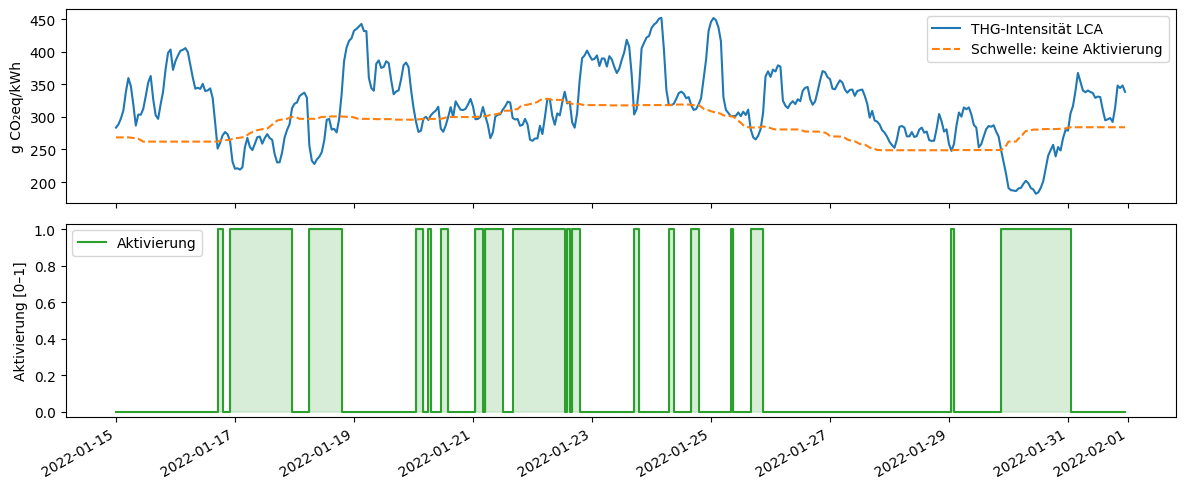

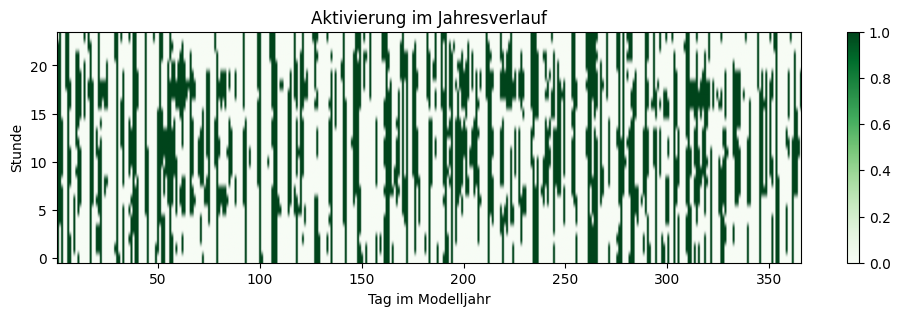

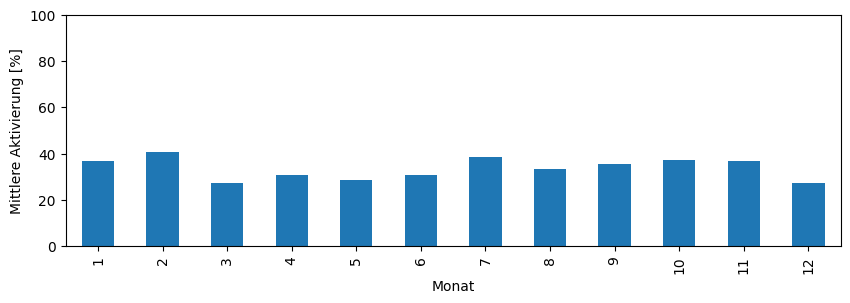

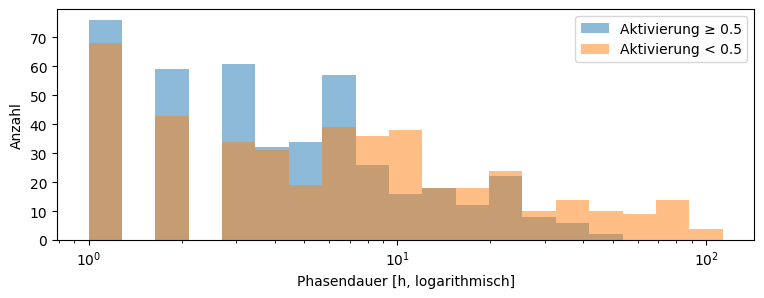

In [ ]:
# EXPERIMENT A – diese Werte verändern
year = 2022
source = "co2"
method = "rolling"
share = .30
window = (0,72)  # (Stunden davor, Stunden danach)
threshold = 100  # nur bei fixed; Originaleinheit der Quelle
interval = ("2022-01-15", "2022-01-31")  # Start, Ende einschließlich bei Datumsangaben
phase_cutoff = .5

x, low, high, signal = make_signal(year,source,method,share,window,threshold)
display(pd.DataFrame({"Gesamtjahr":stats(signal,phase_cutoff),
                      "Gewählter Zeitraum":stats(detail(signal,interval),phase_cutoff)}).round(2))
200200assdf2
axasdasdasd



4232asdasdasdasdasdadasdasd

,wind,exaa,mc,co2
Mittlerer Aktivierungsgrad [%],29.94,30.00,30.00,29.99
Äquivalente Vollaktivierungsstunden [h],2623.00,2628.00,2628.00,2627.00
Stunden mit Aktivierung > 0 [h],2623.00,2628.00,2628.00,2627.00
"Stunden mit Aktivierung ≥ 0,9 [h]",2623.00,2628.00,2628.00,2627.00
Stunden mit Aktivierung ≥ 0.5 [h],2623.00,2628.00,2628.00,2627.00
Anteil Stunden ≥ 0.5 [%],29.94,30.00,30.00,29.99
Aktivierungsphasen,253.00,252.00,280.00,175.00
Mittlere Aktivierungsdauer [h],10.37,10.43,9.39,15.01
Median Aktivierungsdauer [h],5.00,6.00,5.00,5.00
Mittlere Nichtaktivierungsdauer [h],24.26,24.43,21.98,35.05


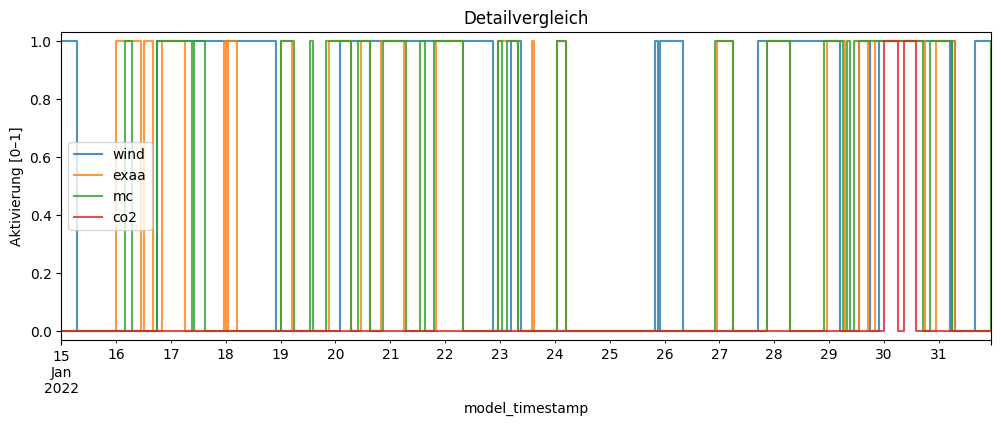

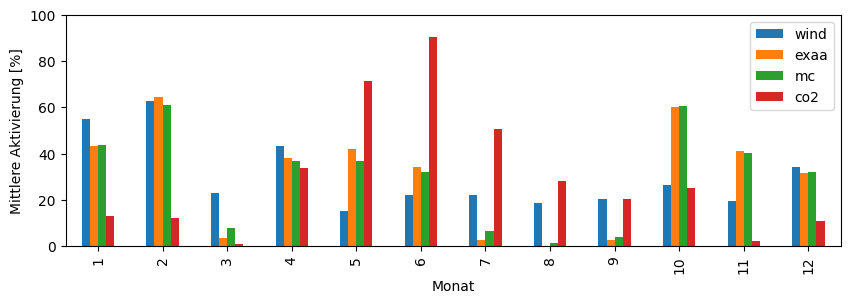

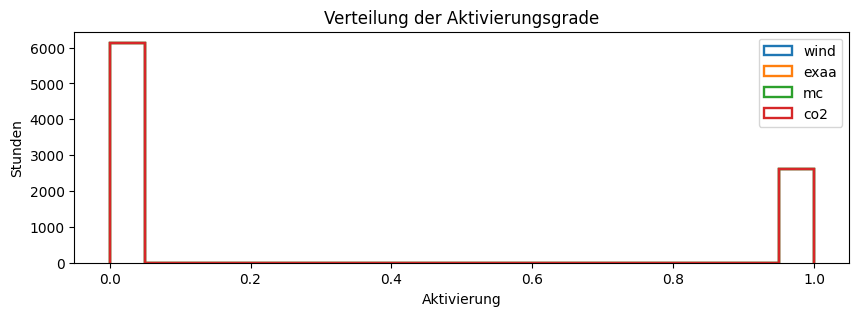

In [4]:
# EXPERIMENT A – Signalherkunft bei ähnlichem Freigabeanteil vergleichen
sources = ["wind", "exaa", "mc", "co2"]  # optional: "load_error"
comparison_method = "annual"
comparison_share = .30
signals_A = {src:make_signal(year,src,method=comparison_method,share=comparison_share,window=window)[3] for src in sources}
compare(signals_A,interval,phase_cutoff)

### Auswertung A – hier antworten
1. Wann treten Freigabephasen auf? Welche saisonalen und täglichen Muster sind erkennbar?
2. Welche Quelle bietet lange zusammenhängende Ladephasen, welche kurze und häufige Phasen?
3. Variiere das Fenster oder den Freigabeanteil bei derselben Quelle. Was verändert sich?
4. Was kann aus dem jeweiligen Signal über Markt-, System- und lokale Netzdienlichkeit abgeleitet werden? Warum darf der Jahresfreigabeanteil allein nicht entscheiden?

**Antwort:** …

## Experiment B – Kontinuierliche Aktivierungsfunktionen

Eine Ramp setzt zwei Schwellen: keine Aktivierung und volle Aktivierung. Dazwischen ist die Aktivierung kontinuierlich. Wir verwenden die günstig orientierte Größe $z=x$ bei Wind bzw. $z=-x$ bei Preis, CO₂ und Lastfehler. Mit $L$ (Aktivierungsbeginn) und $U$ (Vollaktivierung) gilt:

$$a(t)=\operatorname{clip}\left(\frac{z(t)-L(t)}{U(t)-L(t)},0,1\right)$$

- `binary`: $s=1$ oberhalb der Schwelle, sonst 0.
- `linear`: $s=a$.
- `smoothstep`: $s=3a^2-2a^3$.
- `sigmoid`: logistische S-Kurve, auf exakt 0 und 1 an den Ramp-Grenzen skaliert.

Bei gleichen Quantilschwellen wird eine strikte binäre Schwelle verwendet. Für kontinuierliche Quantilmethoden bedeutet `share = (0.20, 0.50)`: Die günstigsten ca. 20 % werden voll aktiviert; bis ca. 50 % der günstigsten Stunden ist eine Aktivierung möglich. Dazwischen wird moduliert. Die tatsächlichen Anteile und Intensitäten sind zu prüfen. Für `fixed` ist `threshold` ein Tupel `(keine Aktivierung, volle Aktivierung)` in Originaleinheiten, z. B. `(100, 30)` bei Preis oder `(500, 1500)` bei Wind. Bei `binary` bleiben `share` und `threshold` einzelne Zahlen.

**Vergleichsmaß:** Bei Stundenwerten ist $\sum_t s(t)\cdot1\,\mathrm{h}$ die Zahl der äquivalenten Vollaktivierungsstunden. Sie ist keine Energie in kWh. Für Phasenstatistiken definieren wir eine einheitliche Analyseschwelle (z. B. 0,5); diese ist keine zusätzliche Regelungsgrenze.

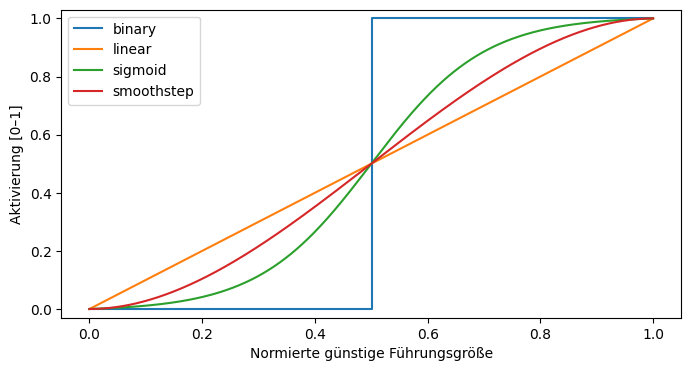

In [5]:
# Aktivierungsfunktionen im normierten Ramp-Bereich
z = np.linspace(0,1,501)
fig,ax=plt.subplots(figsize=(8,4))
ax.step(z,(z>.5).astype(float),where="post",label="binary")
for kind in ["linear","sigmoid","smoothstep"]:
    ax.plot(z,activation_curve(z,kind),label=kind)
ax.set(xlabel="Normierte günstige Führungsgröße",ylabel="Aktivierung [0–1]",ylim=(-.03,1.03)); ax.legend(); plt.show()

,Ergebnis
Mittlerer Aktivierungsgrad [%],37.48
Äquivalente Vollaktivierungsstunden [h],3282.91
Stunden mit Aktivierung > 0 [h],4259.00
"Stunden mit Aktivierung ≥ 0,9 [h]",2531.00
Stunden mit Aktivierung ≥ 0.5 [h],3283.00
Anteil Stunden ≥ 0.5 [%],37.48
Aktivierungsphasen,580.00
Mittlere Aktivierungsdauer [h],5.66
Median Aktivierungsdauer [h],4.00
Mittlere Nichtaktivierungsdauer [h],9.43


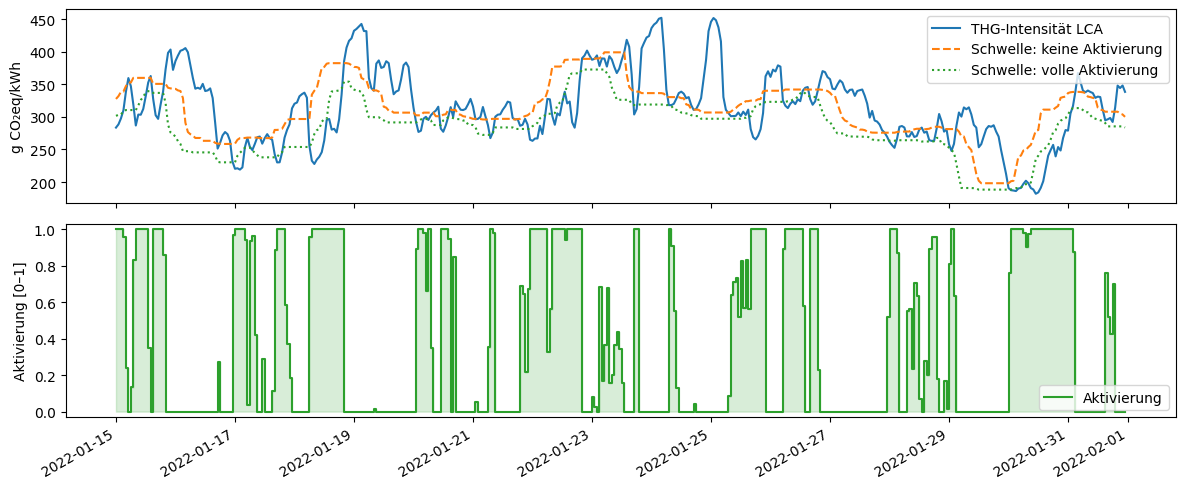

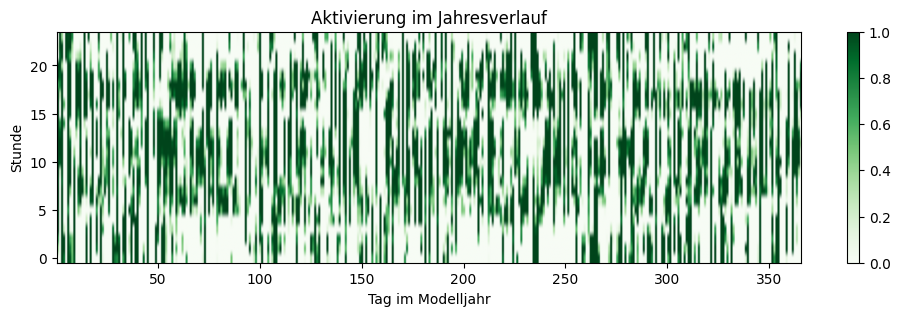

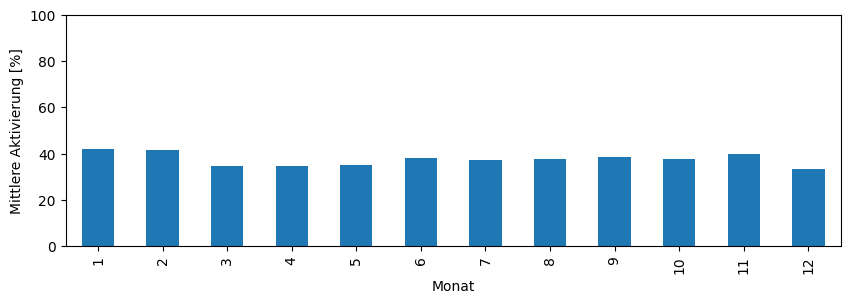

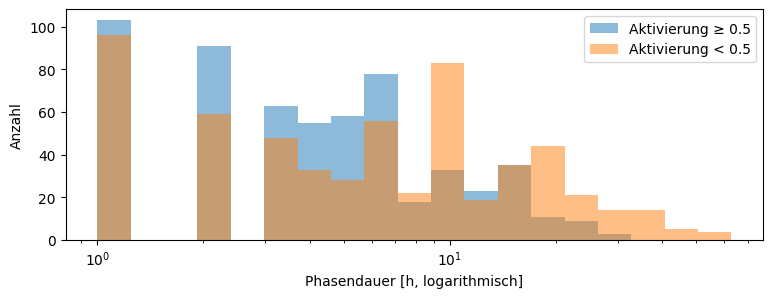

In [6]:
# EXPERIMENT B – diese Werte verändern
source_B = "co2"
method_B = "rolling"
window_B = (0,24)
share_B = (.20,.50)  # (Vollaktivierung, Aktivierungsbeginn)
threshold_B = (250,100)  # nur fixed: (keine, volle Aktivierung)
activation_B = "linear"  # linear, sigmoid, smoothstep
x_B,low_B,high_B,signal_B = make_signal(year,source_B,method_B,share_B,window_B,threshold_B,activation_B)
display(stats(signal_B,phase_cutoff).round(2).to_frame("Ergebnis"))
visualize(x_B,low_B,high_B,signal_B,source_B,interval,phase_cutoff)

,Binär,Linear,Sigmoid,Smoothstep
Mittlerer Aktivierungsgrad [%],38.45,37.48,37.50,37.52
Äquivalente Vollaktivierungsstunden [h],3368.00,3282.91,3285.01,3286.61
Stunden mit Aktivierung > 0 [h],3368.00,4259.00,4259.00,4259.00
"Stunden mit Aktivierung ≥ 0,9 [h]",3368.00,2531.00,2909.00,2720.00
Stunden mit Aktivierung ≥ 0.5 [h],3368.00,3283.00,3283.00,3283.00
Anteil Stunden ≥ 0.5 [%],38.45,37.48,37.48,37.48
Aktivierungsphasen,616.00,580.00,580.00,580.00
Mittlere Aktivierungsdauer [h],5.47,5.66,5.66,5.66
Median Aktivierungsdauer [h],4.00,4.00,4.00,4.00
Mittlere Nichtaktivierungsdauer [h],8.74,9.43,9.43,9.43


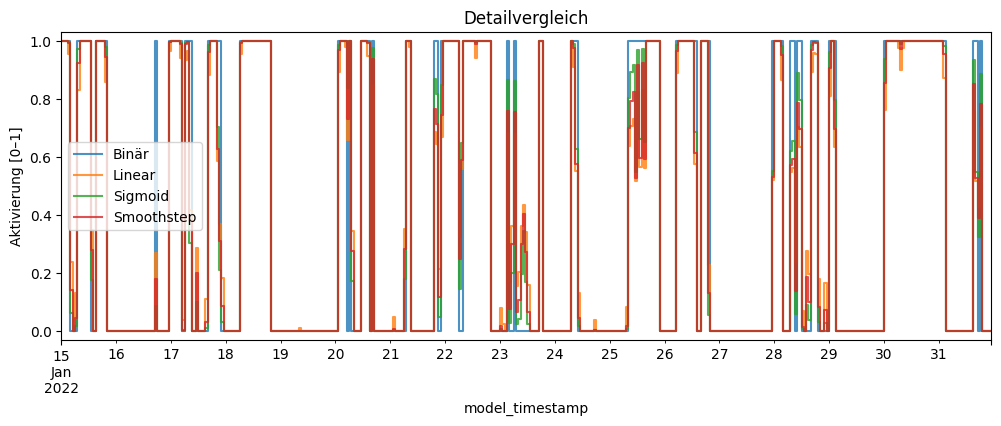

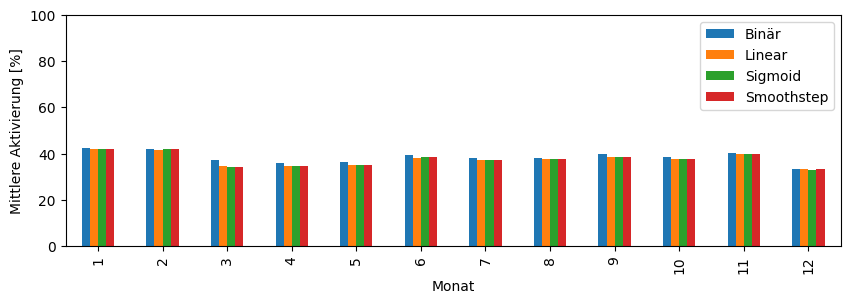

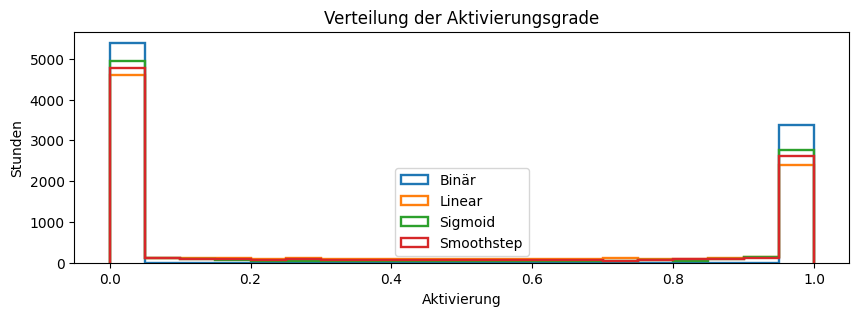

In [7]:
# EXPERIMENT B – Aktivierungsfunktionen bei gleicher Referenz vergleichen
binary_share = .35
binary_threshold = 175  # nur fixed; bei anderer Quelle anpassen
variants_B = [
    dict(name="Binär", activation="binary", share=binary_share, threshold=binary_threshold),
    dict(name="Linear", activation="linear", share=share_B, threshold=threshold_B),
    dict(name="Sigmoid", activation="sigmoid", share=share_B, threshold=threshold_B),
    dict(name="Smoothstep", activation="smoothstep", share=share_B, threshold=threshold_B),
]
signals_B = {v["name"]:make_signal(year,source_B,method=method_B,window=window_B,
                    **{k:a for k,a in v.items() if k!="name"})[3] for v in variants_B}
compare(signals_B,interval,phase_cutoff)

### Auswertung B – hier antworten
1. Welche Unterschiede zeigen sich im Detailverlauf und in der Verteilung der Aktivierungsgrade?
2. Sind die äquivalenten Vollaktivierungsstunden ähnlich? Verändere `binary_share` oder bei `fixed` den Schwellenwert, bis der binäre und der lineare Fall möglichst ähnlich sind. Vergleiche dann die Phasendauern und Signaländerungen.
3. Welche Funktion erscheint für modulierende Geräte, welche für diskrete Betriebszustände sinnvoll? Welche Einschränkungen erwartest du?
4. Wie könnte das Signal in eine Sollwertverschiebung oder flexible Ladeleistung umgesetzt werden?

**Antwort:** …

## Export für PEExcel

Wähle eine Variante aus A oder B. Exportiert werden 8760 Werte (ohne Kopfzeile), eine dokumentierte Zeitreihe und die Parameter. **Das kontinuierliche Format ist ein vorgeschlagenes Austauschformat; ob die konkrete PEExcel-Version reelle Werte verarbeitet und wie die Zeitachse zuzuordnen ist, muss vor der Simulation geprüft werden.**

In [8]:
# EXPERIMENT – Signal auswählen
experiment = "B"  # A oder B
selected = "Linear"  # A: Quellenname (z. B. "wind"), B: Variantenname
if experiment == "A":
    s = signals_A[selected]
    params = dict(source=selected,method=comparison_method,share=comparison_share,window=window,activation="binary")
else:
    s = signals_B[selected]
    params = dict(source=source_B,method=method_B,window=window_B,
                  **{k:v for k,v in next(v for v in variants_B if v["name"]==selected).items() if k!="name"})
export_signal(s,year,selected,params,"signal_AB")

output\signal_AB_2022_Linear.csv – 8760 Stunden


### Schlussfolgerung und Abgabe
Dokumentiere die gewählten Parameter, die wichtigsten Kennzahlen und die fachliche Begründung. Speichere das ausgeführte Notebook und die exportierte Signaldatei. In Notebook 02 wird das Signal auf die zeitlichen Eigenschaften eines Gebäudes abgestimmt.